# Significant Motif TFs Scatter Plot

In [21]:
import numpy as np
import pandas as pd
import os

In [22]:
# directory and data file settings
modisco_f = "/ix/djishnu/Aaron_F/proteomics_proj/Results/modisco/out_files/sig_UT_modisco_tomtomExpanded_TFs_withLabels.csv"
homer_f = "/ix/djishnu/Aaron_F/proteomics_proj/Results/DEG_motif_enrichment/common_degs_enr/sig_TF_results/out_files/sig_tomtom_TFs_withLabels.csv"
DESites_f = "/ix/djishnu/Aaron_F/proteomics_proj/Results/pairwise_DE_sites_analysis/out_files/pairwise_DEsites_9_clusters_ordered.csv"

out_dir = "/ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig3/sig_motif_res"

os.makedirs(out_dir, exist_ok=True)
os.makedirs(f"{out_dir}/figures", exist_ok=True)
os.makedirs(f"{out_dir}/out_files", exist_ok=True)

In [23]:
# load results
modisco_tfs = pd.read_csv(modisco_f)
homer_tfs = pd.read_csv(homer_f)
des_info = pd.read_csv(DESites_f)
print(modisco_tfs.head(), modisco_tfs.shape)
print(homer_tfs.head(), homer_tfs.shape)
print(des_info.head())

             query_pattern            target_id tf_symbol       p_value  \
0   pos_patterns.pattern_4    SP3.H14CORE.0.P.B       Sp3  4.813110e-27   
1   pos_patterns.pattern_4    SP1.H14CORE.2.P.B       Sp1  3.584510e-24   
2  pos_patterns.pattern_21  ZN143.H14CORE.0.P.B    Znf143  3.505850e-23   
3   pos_patterns.pattern_4   KLF9.H14CORE.1.P.B      Klf9  2.832910e-22   
4   pos_patterns.pattern_1   CTCF.H14CORE.0.P.B      Ctcf  3.185490e-20   

        e_value       q_value  is_expressed  is_deg  is_des  
0  7.676920e-24  1.463970e-23          True   False   False  
1  5.717290e-21  5.451360e-21          True   False   False  
2  5.591840e-20  1.118370e-19         False   False   False  
3  4.518490e-19  2.872220e-19          True   False   False  
4  5.080860e-17  1.016160e-16          True   False   False   (350, 9)
              target_id tf_symbol       p_value       e_value       q_value  \
0  IRF9.H14CORE.0.PSM.A      Irf9  1.885730e-14  3.007740e-11  5.985070e-11   
1   IRF8.H

In [24]:
expressed_modisco_tfs = modisco_tfs.loc[
    modisco_tfs.is_expressed,
    ["tf_symbol", "q_value"]
].copy()
expressed_homer_tfs = homer_tfs.loc[
    homer_tfs.is_expressed,
    ["tf_symbol", "q_value"]
].copy()

In [25]:
# Remove CTCF (generic) to make axis lower
expressed_modisco_tfs = expressed_modisco_tfs.loc[
    expressed_modisco_tfs.tf_symbol != "Ctcf",
].copy()

In [26]:
# change coloring to make yellow lighter:
des_info.loc[des_info.cluster==2, "cluster_color"] = "#e0cc8f"

## Final plot — pie-marker scatter of motif enrichment q-values

9 TF(s) exceed the shared x-axis ceiling (11.76) and are shown clipped at the boundary


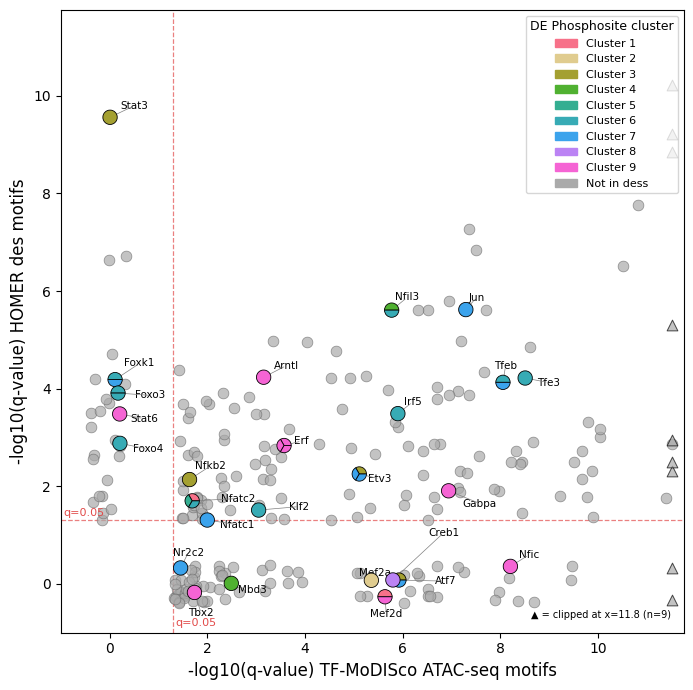

In [27]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Wedge
from adjustText import adjust_text

def draw_pie_marker(ax, x, y, colors, size=80, zorder=4):
    n = len(colors)
    angles = np.linspace(0, 360, n + 1)
    fig = ax.get_figure()
    ax_width_inch = ax.get_position().width * fig.get_figwidth()
    ax_xrange = ax.get_xlim()[1] - ax.get_xlim()[0]
    points_per_inch = 72
    radius = (np.sqrt(size) / points_per_inch) * (ax_xrange / ax_width_inch) * 0.5
    for i, color in enumerate(colors):
        wedge = Wedge(
            center=(x, y),
            r=radius,
            theta1=angles[i],
            theta2=angles[i + 1],
            facecolor=color,
            edgecolor="black",
            linewidth=0.6,
            zorder=zorder
        )
        ax.add_patch(wedge)

# Outer merge — keep all TFs from either source
merged = expressed_homer_tfs[["tf_symbol", "q_value"]].merge(
    expressed_modisco_tfs[["tf_symbol", "q_value"]],
    on="tf_symbol",
    how="outer",
    suffixes=("_homer", "_modisco")
)

# Fill missing q_values with 1 → -log10(1) = 0
merged["q_value_homer"] = merged["q_value_homer"].fillna(1)
merged["q_value_modisco"] = merged["q_value_modisco"].fillna(1)

merged["log_q_homer"] = -np.log10(merged["q_value_homer"])
merged["log_q_modisco"] = -np.log10(merged["q_value_modisco"])

# Add jitter for zero points
np.random.seed(42)
merged["plot_x"] = merged["log_q_modisco"].copy()
merged["plot_y"] = merged["log_q_homer"].copy()

homer_zero = merged["log_q_homer"] == 0
modisco_zero = merged["log_q_modisco"] == 0
merged.loc[homer_zero, "plot_y"] = np.random.uniform(-0.4, 0.4, homer_zero.sum())
merged.loc[modisco_zero, "plot_x"] = np.random.uniform(-0.4, 0.4, modisco_zero.sum())

threshold = -np.log10(0.05)

# Build per-gene color list to handle duplicate phosphosites
gene_to_colors = des_info.groupby("geneSymbol")["cluster_color"].apply(list).to_dict()
merged["in_des"] = merged["tf_symbol"].isin(gene_to_colors)

fig, ax = plt.subplots(figsize=(8, 7))

# ---- shared axis ceiling, based on y_max (NOT x_max) -- some
# non-des TFs have very high TF-MoDISco significance that we don't
# care about resolving exactly, so the x-axis range is driven by what
# the y-axis actually needs, not by those outliers. Points beyond the
# ceiling are CLIPPED (not dropped) and flagged so they render as a
# distinct marker rather than looking like they genuinely sit there.
x_max = merged["log_q_modisco"].max()
y_max = merged["log_q_homer"].max()
shared_limit = y_max * 1.15

merged["x_clipped"] = merged["plot_x"] > shared_limit
n_clipped = merged["x_clipped"].sum()
merged["plot_x_display"] = merged["plot_x"].clip(upper=shared_limit * 0.98)  # just inside the border, not on top of it
print(f"{n_clipped} TF(s) exceed the shared x-axis ceiling ({shared_limit:.2f}) and are shown clipped at the boundary")

# Threshold lines
ax.axvline(x=threshold, color="#E24B4A", linestyle="--", linewidth=0.9, alpha=0.7, zorder=2)
ax.axhline(y=threshold, color="#E24B4A", linestyle="--", linewidth=0.9, alpha=0.7, zorder=2)

# Dynamic axis limits — set BEFORE drawing pie markers so radius calc is correct
ax.set_xlim(-1, shared_limit)
ax.set_ylim(-1, shared_limit)
ax.set_aspect('equal')

# Non-des points — split into normal vs clipped so clipped ones get a
# distinct marker (triangle) instead of a circle sitting at the border
non_des = merged[~merged["in_des"]]
non_des_normal = non_des[~non_des["x_clipped"]]
non_des_clipped = non_des[non_des["x_clipped"]]

ax.scatter(
    non_des_normal["plot_x_display"], non_des_normal["plot_y"],
    s=60, alpha=0.7, color="#AAAAAA",
    edgecolors="#666666", linewidths=0.5, zorder=3
)
if len(non_des_clipped) > 0:
    ax.scatter(
        non_des_clipped["plot_x_display"], non_des_clipped["plot_y"],
        s=60, alpha=0.7, color="#AAAAAA", marker="^",
        edgecolors="black", linewidths=0.7, zorder=3
    )

# des points — pie markers (also clipped if needed, using the same display column)
des_points = merged[merged["in_des"]]
for _, row in des_points.iterrows():
    colors = gene_to_colors.get(row["tf_symbol"], ["#AAAAAA"])
    draw_pie_marker(ax, row["plot_x_display"], row["plot_y"], colors, size=80, zorder=4)
    if row["x_clipped"]:
        ax.plot(row["plot_x_display"], row["plot_y"], marker="^", markersize=4,
                color="none", markeredgecolor="black", zorder=5)

# Label only des-overlapping TFs
label_df = merged[merged["in_des"]]
texts = [
    ax.text(row["plot_x_display"], row["plot_y"], row["tf_symbol"], fontsize=7.5)
    for _, row in label_df.iterrows()
]
adjust_text(
    texts,
    x=merged["plot_x_display"].values,
    y=merged["plot_y"].values,
    ax=ax,
    arrowprops=dict(arrowstyle="-", color="gray", lw=0.5),
    expand=(1.5, 2.0),
    force_text=(0.8, 1.0),
    force_points=(0.8, 1.2)
)

# Legend
unique_clusters = des_info[["cluster", "cluster_color"]].drop_duplicates().sort_values("cluster")
legend_handles = [
    mpatches.Patch(color=row["cluster_color"], label=f"Cluster {int(row['cluster'])}")
    for _, row in unique_clusters.iterrows()
]
legend_handles.append(mpatches.Patch(color="#AAAAAA", label="Not in dess"))
ax.legend(handles=legend_handles, fontsize=8, title="DE Phosphosite cluster",
          title_fontsize=9, loc="upper right", framealpha=0.8)

ax.set_xlabel("-log10(q-value) TF-MoDISco ATAC-seq motifs", fontsize=12)
ax.set_ylabel("-log10(q-value) HOMER des motifs", fontsize=12)

ax.text(threshold + 0.05, ax.get_ylim()[0] + 0.1, "q=0.05",
        color="#E24B4A", fontsize=8, va="bottom")
ax.text(ax.get_xlim()[0] + 0.05, threshold + 0.05, "q=0.05",
        color="#E24B4A", fontsize=8, va="bottom")

if n_clipped > 0:
    ax.text(0.98, 0.02, f"\u25b2 = clipped at x={shared_limit:.1f} (n={n_clipped})",
            transform=ax.transAxes, ha="right", va="bottom", fontsize=7, color="black")

plt.tight_layout()
plt.savefig(f"{out_dir}/figures/motif_based_tf_DES_colored_scatterPlot_qvalues.png", dpi=200, bbox_inches="tight")
plt.savefig(f"{out_dir}/figures/motif_based_tf_DES_colored_scatterPlot_qvalues.svg", dpi=200, bbox_inches="tight")
plt.show()

In [29]:
merged.to_csv(f"{out_dir}/out_files/motif_based_scatterPlot_data.csv")